# Exercise: Image Classification with CNNs on Fashion-MNIST

## Objective

In this exercise, you will train a **Convolutional Neural Network (CNN)** to classify clothing images from the **Fashion-MNIST** dataset.

By the end of the exercise, you should be able to:

- download and inspect an image dataset using `torchvision`;
- understand the shape of image tensors used by CNNs;
- create training, validation, and test data loaders;
- construct a CNN using convolution, activation, pooling, and fully connected layers;
- understand how the spatial dimensions of feature maps change;
- train a CNN using forward propagation, loss computation, backpropagation, and an optimizer;
- compare training and validation performance;
- compute classification accuracy;
- identify signs of overfitting and underfitting;
- save and reload a trained CNN;
- experiment with CNN architecture and hyperparameters.

---

## Dataset

Fashion-MNIST contains **28 × 28 grayscale images** belonging to 10 clothing categories.

The classes are:

| Label | Class |
|---:|---|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

Unlike the original MNIST digit dataset, Fashion-MNIST is a slightly more challenging image-classification problem.

---

## Rules for the exercise

Complete every cell marked:

```python
# TODO
```

Run the notebook sequentially from top to bottom.

Do not immediately copy a complete CNN implementation from the internet. The goal is to understand **what each layer does and why it is needed**.
Also jusitfy **the choice of each hyperparameter, choice of loss function and optimizer**

## 1. Imports and reproducibility

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Download Fashion-MNIST

`torchvision.datasets.FashionMNIST` can automatically download the dataset. We first convert every image into a PyTorch tensor using:

```python 
transforms.ToTensor()
```
For a grayscale image, the tensor shape is: $(C,H,W)$

where: 
- \(C\) = number of channels,
- \(H\) = height,
- \(W\) = width.

For Fashion-MNIST: $(1,28,28)$

Create the training and test datasets using:
```python 
root="./data"
download=True
```

In [2]:
transform = transforms.ToTensor()
train_full = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

print("Training samples:", len(train_full))
print("Test samples:", len(test_dataset))

100%|██████████| 26.4M/26.4M [00:03<00:00, 7.09MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 2.09MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.92MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.47MB/s]

Training samples: 60000
Test samples: 10000


Before designing a neural network, always inspect your data.

Image shape: torch.Size([1, 28, 28])
Label: 9
Class: Ankle boot
Minimum pixel value: 0.0
Maximum pixel value: 1.0


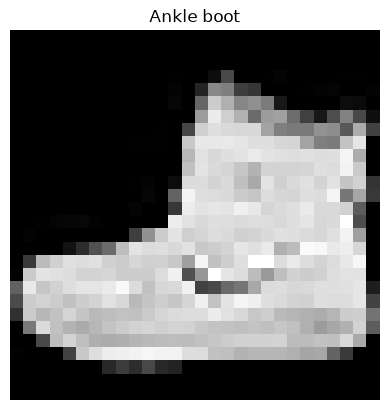

In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

# TODO: Extract one image and its label.
image, label = train_full[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class:", class_names[label])
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis("off")
plt.show()

## 4. Visualize several images

Looking at several examples is useful for understanding the classification problem.


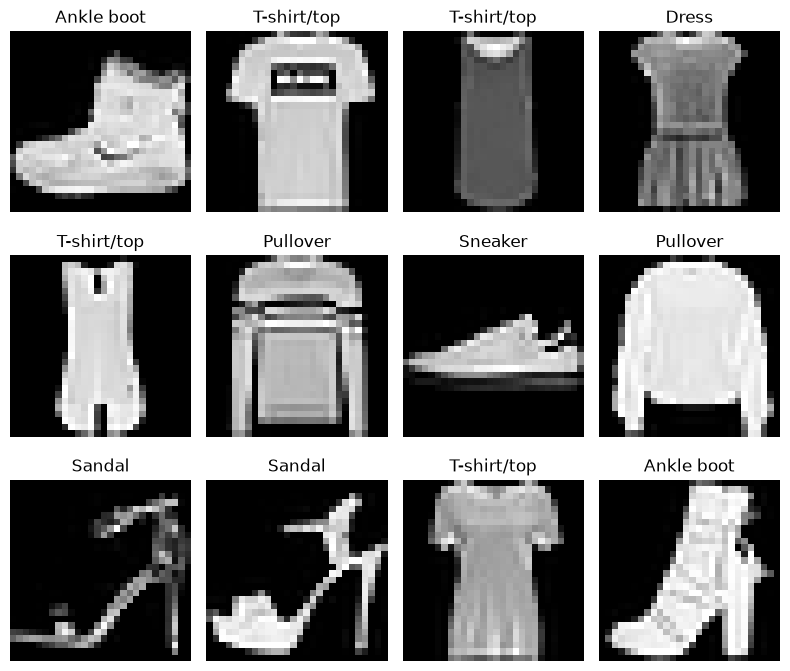

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(8, 7))

for i, ax in enumerate(axes.flat):
    image, label = train_full[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Create training and validation sets

The original Fashion-MNIST training set will be divided into:

- **training set**: used to update network weights;
- **validation set**: used to monitor generalization during training.

The test set must remain untouched until the final evaluation.

We will use:

- 50,000 training images;
- 10,000 validation images;
- 10,000 test images.

In [9]:
train_size = 50_000
val_size = 10_000

generator = torch.Generator().manual_seed(SEED)
# TODO: Split train_full into training and validation sets.
train_dataset, val_dataset = random_split(train_full, [train_size, val_size], generator=generator,)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Training: 50000
Validation: 10000
Test: 10000


## 6. Create DataLoaders

In [10]:
batch_size = 64
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
)
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])


# Part II — Understanding the CNN

## 7. Convolution layer

For a convolutional layer:

```python
nn.Conv2d(
    in_channels,
    out_channels,
    kernel_size,
    stride,
    padding
)
```

The output spatial dimension is:

$H_{\text{out}}= \left\lfloor\frac{H_{\text{in}} + 2P - K}{S} \right\rfloor + 1$

and similarly for the width.

where:

- \(K\) = kernel size;
- \(S\) = stride;
- \(P\) = padding.

---
Consider:

```python
nn.Conv2d(
    in_channels=1,
    out_channels=16,
    kernel_size=3,
    stride=1,
    padding=1
)
```

Given an input image of:

```text
1 × 28 × 28
```

answer the following **before running any code**:

1. How many kernels are learned?
2. What is the size of each kernel?
3. What will the output tensor shape be for one image?
4. Why does the spatial size remain 28 × 28?

### Answers

1.The layer learns 16 kernels, because out_channels=16. Each kernel acts as a small filter that looks for a specific pattern in the image.

2.Each kernel has a size of 1 × 3 × 3. The 3 × 3 comes from kernel_size=3, and the depth of 1 comes from in_channels=1, since a grayscale image has only one channel. Each kernel therefore has 9 weights plus 1 bias.

3.The output shape is 16 × 28 × 28. Each of the 16 kernels slides over the whole image and produces one 28 × 28 feature map, which shows where its pattern appears in the image.

4.Without padding, a 3 × 3 kernel cannot be centered on the border pixels, so the output would shrink to 26 × 26. The padding of 1 adds a border of zeros around the image, which allows the kernel to reach the edges. Combined with a stride of 1, the spatial size is preserved.

In [11]:
conv_test = nn.Conv2d(
    in_channels=1,
    out_channels=16,
    kernel_size=3,
    stride=1,
    padding=1,
)

x = torch.randn(1, 1, 28, 28)
y = conv_test(x)

print("Input shape :", x.shape)
print("Output shape:", y.shape)

Input shape : torch.Size([1, 1, 28, 28])
Output shape: torch.Size([1, 16, 28, 28])


## 8. Pooling

A max-pooling operation such as:

```python
nn.MaxPool2d(kernel_size=2, stride=2)
```

reduces the spatial dimensions.

For example:

```text
16 × 28 × 28
```

becomes:

```text
16 × 14 × 14
```

In [13]:
pool = nn.MaxPool2d(kernel_size=2, stride=2)
# Pooling keeps only the maximum value of each 2x2 square of the feature maps.
# Why: reduces computations and parameters, keeps the strongest features,( on l'applique sur feature maps et non sur l'image)
x = torch.randn(1, 16, 28, 28)
y = pool(x)

print("Before pooling:", x.shape)
print("After pooling :", y.shape)

Before pooling: torch.Size([1, 16, 28, 28])
After pooling : torch.Size([1, 16, 14, 14])


## 9. Activation functions

A convolution is a linear operation. Without nonlinear activation functions, stacking several linear layers would still behave like one large linear transformation.

We will use:

```python
nn.ReLU()
```

## 10. Design the CNN

Create your own network with the final layer contains **10 outputs**, one for each Fashion-MNIST class.

These outputs are called **logits**.

In [27]:
class FashionCNN(nn.Module):
    def __init__(self):
    ## TO DO create your network
        super().__init__()  
        # Feature extractor: detects patterns in the image
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),   #filtres de 3x3, 16 filtres → 16 feature maps, 1 canal en entrée (image en gris)
            nn.ReLU(),
            nn.MaxPool2d(2),                              

            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # 32 filtres → 32 feature maps, 16 canaux en entrée = les 16 feature maps de la couche précédente
            nn.ReLU(),
            nn.MaxPool2d(2),                              
        )

        # Classifier: turns the features into 10 class scores
        self.classifier = nn.Sequential(
            nn.Flatten(),                 # 32x7x7 -> 1568 values
            nn.Linear(32 * 7 * 7, 64),   # hidden fully connected layer 128 its an hyperparametre
            nn.ReLU(),
            nn.Linear(64, 10),           # 10 logits, one per class
        )


    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = FashionCNN().to(device)
print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)


### Explanation of our choices in the CNN

Our network has two parts. The first part (features) contains two convolutional blocks, each made of a convolution, a ReLU activation and a max pooling layer. The first convolution uses 16 filters to detect simple patterns like edges, and the second uses 32 filters to combine these edges into more complex shapes.

We double the number of filters because the image gets smaller after each pooling, so we keep less spatial detail but learn more types of patterns.

We use 3 × 3 kernels with a padding of 1 so that the convolution keeps the same size, and the pooling divides it by 2 each time (28 → 14 → 7). We chose two blocks because the images are small and simple.

The second part (classifier) makes the final decision. "Flatten" turns the 32 × 7 × 7 feature maps into a vector of 1568 values. Then a hidden layer of 128 neurons combines these features. 

The value 128 is a hyperparameter that we chose ourselves: we start with 128 because it seems like a good compromise between learning enough and avoiding overfitting, and we will check the results on the validation set to see if another value works better.

ReLU is used after each layer because without it the network would only be a linear model. The last layer has 10 outputs, one for each class.

### We treid 128 neurons but it gives an overfitting 

## 11. Verify the output shape

A very useful debugging technique is to send a dummy batch through the network.

In [28]:
dummy_batch = torch.randn(64, 1, 28, 28).to(device)

with torch.no_grad():
    dummy_output = model(dummy_batch)

print("Input shape :", dummy_batch.shape)
print("Output shape:", dummy_output.shape)

Input shape : torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


# Part III — Training the CNN

## 13. Loss function

This is a 10-class classification problem.
Justify the choice of loss function and try different loss functions.

In [29]:
criterion = nn.CrossEntropyLoss()                      # baseline
# criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
# criterion = nn.MultiMarginLoss()                    

We use `nn.CrossEntropyLoss` because this is a multi-class classification problem with 10 classes and only one correct class per image. It applies a Softmax to the logits to get probabilities, then penalizes the model when the probability of the correct class is low.
A confident but wrong prediction gives a large loss, which produces strong gradients to correct the weights. It also takes the labels directly as class numbers (0 to 9). 

MSE is not suitable here because it is designed for regression, not for classification.

We also try CrossEntropyLoss(label_smoothing=0.1), which prevents the model from being overconfident, and MultiMarginLoss, an SVM-style loss that only requires the correct class score to be higher than the others by a margin. 

We compare them using the validation accuracy.

## 14. Optimizer

The optimizer updates the network parameters using gradients computed by backpropagation.
Justify the choice of optimizer and try different optimizer functions

In [30]:
learning_rate = 0.001

# TODO: Create the optimizer.
optimizer =  torch.optim.Adam(model.parameters(), lr=learning_rate)
# optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)   
# optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001)            
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


We use the Adam optimizer with a learning rate of 0.001. Adam combines momentum (it uses an average of the previous gradients, so the updates are smoother) and an adaptive learning rate for each weight. It usually converges faster than plain SGD and needs less tuning. 

The learning rate 0.001 is the default value recommended for Adam: a larger value could make the loss unstable, and a smaller one would make training slow. Like the other hyperparameters, it is a starting choice that we check with the validation results.

We also try SGD with momentum (lr = 0.01, momentum = 0.9) and RMSprop (lr = 0.001), and compare them using the validation accuracy.

## 15. Training loop
Train your CNN and then compute the accuracy using:

$\text{Accuracy}=\frac{\text{number of correct predictions}}{\text{number of samples}}\times 100$

In [31]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # TODO 1: Reset gradients.
        optimizer.zero_grad()

        # TODO 2: Forward pass.
        outputs = model(images)

        # TODO 3: Compute loss.
        loss = criterion(outputs, labels)

        # TODO 4: Backpropagation.
        loss.backward()

        # TODO 5: Update network parameters.
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    return epoch_loss, epoch_accuracy

## 16. Validation function

During validation:

- we do **not** update model parameters;
- gradients are unnecessary;
- dropout and batch-normalization layers, if present, should behave in evaluation mode.


In [32]:
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            # TODO: Forward pass.
            outputs = model(images)

            # TODO: Compute loss.
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    return epoch_loss, epoch_accuracy

## 17. Train the network


In [33]:
epochs = 10   #TODO

history = {"train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],}

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device,
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device,
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch  1/10 | Train Loss: 0.5459 | Val Loss: 0.3823 | Train Acc: 80.39% | Val Acc: 86.28%
Epoch  2/10 | Train Loss: 0.3543 | Val Loss: 0.3395 | Train Acc: 87.11% | Val Acc: 87.75%
Epoch  3/10 | Train Loss: 0.3102 | Val Loss: 0.3119 | Train Acc: 88.80% | Val Acc: 88.99%
Epoch  4/10 | Train Loss: 0.2798 | Val Loss: 0.2947 | Train Acc: 89.88% | Val Acc: 89.10%
Epoch  5/10 | Train Loss: 0.2593 | Val Loss: 0.2640 | Train Acc: 90.59% | Val Acc: 90.51%
Epoch  6/10 | Train Loss: 0.2372 | Val Loss: 0.2509 | Train Acc: 91.32% | Val Acc: 91.02%
Epoch  7/10 | Train Loss: 0.2233 | Val Loss: 0.2416 | Train Acc: 91.75% | Val Acc: 91.33%
Epoch  8/10 | Train Loss: 0.2074 | Val Loss: 0.2377 | Train Acc: 92.24% | Val Acc: 91.34%
Epoch  9/10 | Train Loss: 0.1944 | Val Loss: 0.2302 | Train Acc: 92.81% | Val Acc: 91.82%
Epoch 10/10 | Train Loss: 0.1831 | Val Loss: 0.2363 | Train Acc: 93.15% | Val Acc: 91.46%


## 18. Plot training and validation loss

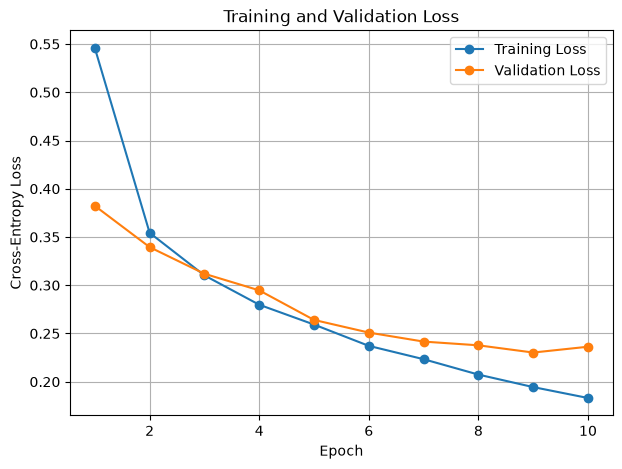

In [34]:
epochs_axis = range(1, epochs + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs_axis, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs_axis, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 19. Plot training and validation accuracy

Accuracy is easier to interpret than loss because it directly tells us the percentage of correctly classified images.

However, accuracy does **not** replace the loss function during training.

### Question:

Plot:

- training accuracy;
- validation accuracy.

Then explain why we usually inspect **both loss and accuracy**.

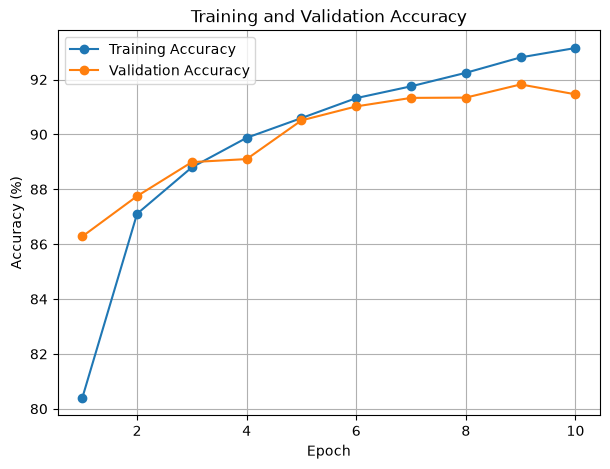

In [35]:
plt.figure(figsize=(7, 5))
plt.plot(epochs_axis, history["train_acc"], marker="o", label="Training Accuracy")
plt.plot(epochs_axis, history["val_acc"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Both accuracies increase together until epoch 5. After that, the training accuracy keeps increasing (about 93% at epoch 10), while the validation accuracy reaches a plateau around 91–92%. 
The best validation accuracy is at epoch 9 (about 91.8%), then it decreases slightly at epoch 10. This confirms the loss curve: there is a small overfitting at the end, but the gap between training and validation stays small (about 1.5%), so the model generalizes well.

We inspect both loss and accuracy because they give different information. Accuracy only checks whether the predicted class is correct, so it is easy to interpret, but it does not show how confident the model is. The loss also measures confidence: a prediction with 51% or 99% on the correct class gives the same accuracy but a very different loss. That is why the loss can detect problems earlier: here, the validation loss increases at epoch 10 while the accuracy barely changes. 

Moreover, accuracy cannot be used to train the model because it is not differentiable (it changes by steps), so we train with the loss and use accuracy to evaluate the results.

# Part IV — Final evaluation

## 20. Test-set performance

The test set should be used only after model development is complete.

### Question

Why would repeatedly checking the test accuracy during model development be a bad practice?

The test set is used to measure how the model performs on new images. If we check it many times during development, we start choosing our model based on the test results, so the model becomes adapted to these specific images. The test accuracy is then too optimistic and does not show the real performance. This is why we make all our choices with the validation set and use the test set only once, at the end.

In [36]:
test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    criterion,
    device,
)

print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss    : 0.2557
Test Accuracy: 90.78%


The model reaches a test accuracy of **90.78%** (test loss 0.2557). This is very close to the validation accuracy (about 91.5%), so the validation set was a good estimate of the real performance and the model generalizes well to new images.

## 21. Inspect individual predictions

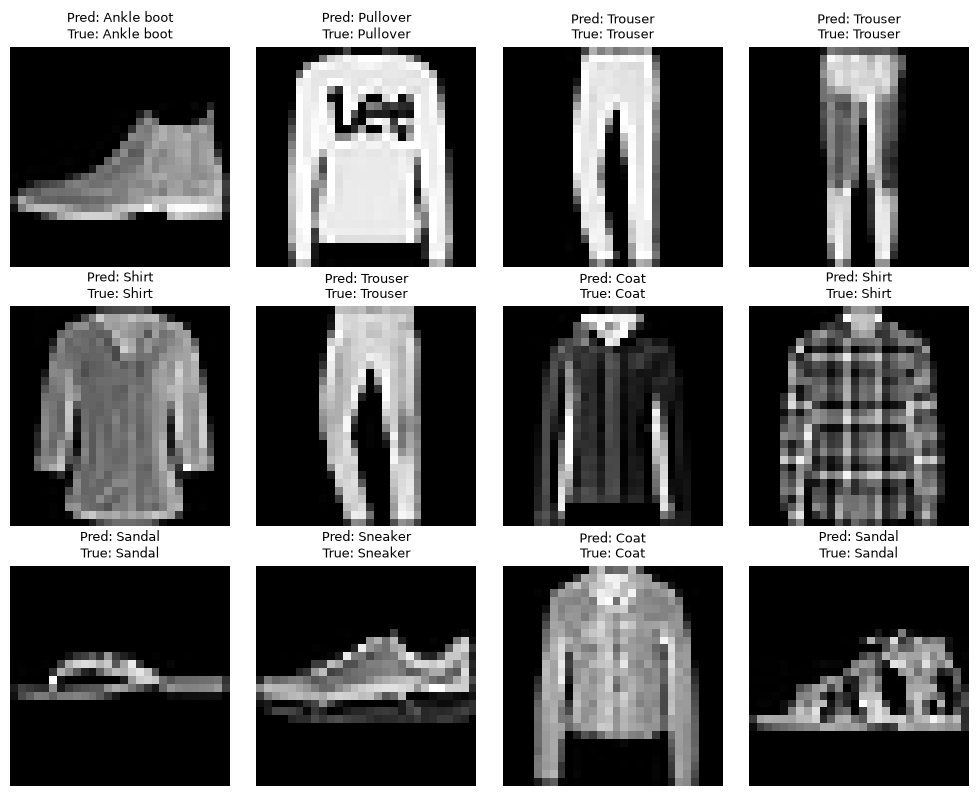

In [37]:
model.eval()

images, labels = next(iter(test_loader))
images_device = images.to(device)

with torch.no_grad():
    outputs = model(images_device)
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    pred_name = class_names[predictions[i].item()]
    true_name = class_names[labels[i].item()]

    ax.set_title(
        f"Pred: {pred_name}\nTrue: {true_name}",
        fontsize=9,
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## 22. Per-class accuracy

A model may perform well overall but poorly on one particular class.
Calculate the classification accuracy separately for each Fashion-MNIST class.
### Questions
1. Which class is easiest for the CNN?
2. Which class is hardest?
3. Why might visually similar classes be confused?

In [38]:
model.eval()

class_correct = [0 for _ in range(10)]
class_total = [0 for _ in range(10)]

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        for label, prediction in zip(labels, predictions):
            label_index = label.item()
            class_total[label_index] += 1

            if prediction.item() == label_index:
                class_correct[label_index] += 1

for i, name in enumerate(class_names):
    accuracy = 100.0 * class_correct[i] / class_total[i]
    print(f"{name:15s}: {accuracy:6.2f}%")

T-shirt/top    :  83.00%
Trouser        :  98.70%
Pullover       :  85.40%
Dress          :  92.90%
Coat           :  83.70%
Sandal         :  98.20%
Shirt          :  76.20%
Sneaker        :  93.70%
Bag            :  97.80%
Ankle boot     :  98.20%


1. The easiest class is **Trouser** (98.70%). These item have a very distinctive shape, so they are easy to recognize.

2. The hardest class is **Shirt** (76.20%), far below the others.

3. Some classes have almost the same shape: a shirt, a T-shirt, a pullover and a coat are all upper-body clothes with a similar outline and sleeves. The differences are small details like buttons, a collar or the texture of the fabric. At a low resolution of 28 × 28 pixels in grayscale, these details are often barely visible, and there are no colors to help. The CNN mostly relies on the global shape, so it can easily mix up these classes.

# Part V — Understanding what the CNN learned

## 23. Feature maps
What is a feature map and visualize it
Run one test image through the **first convolutional layer** and visualize several feature maps.
Do they look like the original image?
Check if you can see evidence of:
- edges;
- textures;
- local shapes;
- intensity transitions?

Feature-map tensor shape: torch.Size([1, 16, 28, 28])


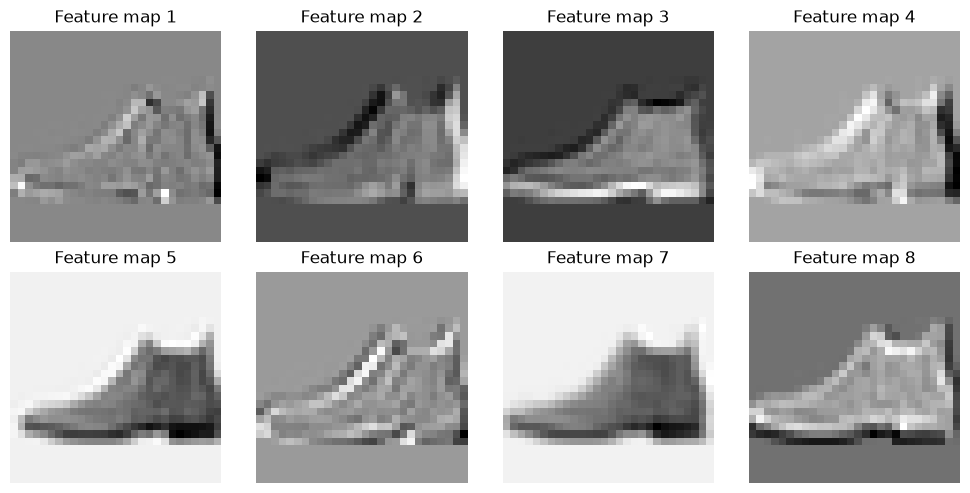

In [39]:
first_conv = model.features[0]

sample_image, sample_label = test_dataset[0]
sample_batch = sample_image.unsqueeze(0).to(device)

with torch.no_grad():
    feature_maps = first_conv(sample_batch).cpu()

print("Feature-map tensor shape:", feature_maps.shape)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, i], cmap="gray")
    ax.set_title(f"Feature map {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

A feature map is the output of one filter: it shows where the filter finds its pattern in the image.

The feature maps still look like the original image, because the first layer only detects simple patterns. But each one highlights something different: some show the edges of the boot, and others some show intensity transitions.

## 24. What exactly is learned?

### Questions

Answer in your own words.

1. What is a convolutional kernel?
2. Are convolutional kernels manually chosen or learned?
3. Why can one convolutional layer contain many kernels?
4. What does `out_channels=32` mean?
5. Why are feature maps different from the original image?
6. What happens to feature abstraction as we move deeper into a CNN?
7. Why do CNNs usually work better than a fully connected network directly applied to raw images?

1. A kernel is a grid that slides over the image, that act as a filter that detects one specific pattern (EX: edges)
2. Convolutional Kernels are learned, generaly we start whit random values, but during training, backpropagation and optimizer they get updated to detect useful patterns for classification.
3. Each Kernel detect only one pattern. thats why we need many kernels to detect a maximums of patterns
4. It means the layer has 32 kernels, so it produces 32 feature maps
5. Because each feature map only shows where one specific pattern appears in the image. It highlights some parts (EX: edges) and ignores others
6. The features become more and more abstract. The first layers detect simple patterns, and deeper layers combine them into more complex shapes.
7. A fully connected network flattens the image, so it loses the spatial structure. It also needs a huge number of weights. A CNN keeps the spatial structure, uses the same small kernel over the whole image, so it has fewer parameters, and it can recognize a pattern wherever it appears in the image.

# Part VI — Model diagnosis

## 25. Overfitting and underfitting

### Case A

Suppose after many epochs:

```text
Training accuracy   = 99%
Validation accuracy = 86%
```

and validation loss starts increasing.

**Question:** What is happening?

---

### Case B

Suppose:

```text
Training accuracy   = 72%
Validation accuracy = 70%
```

and both losses remain relatively high.

**Question:** What is happening?

---

### Case C

Suppose:

```text
Training accuracy   = 92%
Validation accuracy = 91%
Test accuracy       = 90%
```

**Question:** What can you conclude about generalization?

### Answers

Case A : Overfitting  It is almost perfect on the training set but much worse on Validation data, and the increasing validation loss shows it is getting worse on new data
Case B : Underfitting  The model performs badly on both sets, So it is a simple model
Case C : The model generalizes well. The accuracy is high and the three results are very close. There is no real overfitting or underfitting. 

## 26. Regularization experiment

One method for reducing overfitting is **dropout**.

For example:

```python
nn.Dropout(p=0.5)
```

During training, dropout randomly sets some activations to zero.

Create a second model where you add:

```python
nn.Dropout(p=0.5)
```

between the hidden fully connected layer and the final output layer.

Train it and compare:

- training accuracy;
- validation accuracy;
- validation loss.

### Question

Does dropout always improve performance?

In [40]:
# TODO: Create a second CNN architecture with dropout.

class FashionCNNWithDropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),

            # TODO: Add dropout here.
            nn.Dropout(p=0.5),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [41]:
# New model and optimizer for the dropout experiment
model_dropout = FashionCNNWithDropout().to(device)
optimizer_dropout = torch.optim.Adam(model_dropout.parameters(), lr=learning_rate)

history_dropout = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(model_dropout, train_loader, criterion, optimizer_dropout, device)
    val_loss, val_acc = evaluate(model_dropout, val_loader, criterion, device)

    history_dropout["train_loss"].append(train_loss)
    history_dropout["val_loss"].append(val_loss)
    history_dropout["train_acc"].append(train_acc)
    history_dropout["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%"
    )

Epoch  1/10 | Train Loss: 0.6531 | Val Loss: 0.4105 | Train Acc: 76.17% | Val Acc: 85.04%
Epoch  2/10 | Train Loss: 0.4290 | Val Loss: 0.3420 | Train Acc: 84.62% | Val Acc: 87.46%
Epoch  3/10 | Train Loss: 0.3745 | Val Loss: 0.3233 | Train Acc: 86.55% | Val Acc: 87.98%
Epoch  4/10 | Train Loss: 0.3405 | Val Loss: 0.2908 | Train Acc: 87.69% | Val Acc: 89.24%
Epoch  5/10 | Train Loss: 0.3147 | Val Loss: 0.2814 | Train Acc: 88.67% | Val Acc: 89.57%
Epoch  6/10 | Train Loss: 0.2979 | Val Loss: 0.2705 | Train Acc: 89.12% | Val Acc: 90.37%
Epoch  7/10 | Train Loss: 0.2764 | Val Loss: 0.2587 | Train Acc: 89.81% | Val Acc: 90.83%
Epoch  8/10 | Train Loss: 0.2641 | Val Loss: 0.2496 | Train Acc: 90.18% | Val Acc: 90.72%
Epoch  9/10 | Train Loss: 0.2540 | Val Loss: 0.2481 | Train Acc: 90.70% | Val Acc: 90.88%
Epoch 10/10 | Train Loss: 0.2420 | Val Loss: 0.2501 | Train Acc: 91.08% | Val Acc: 90.99%


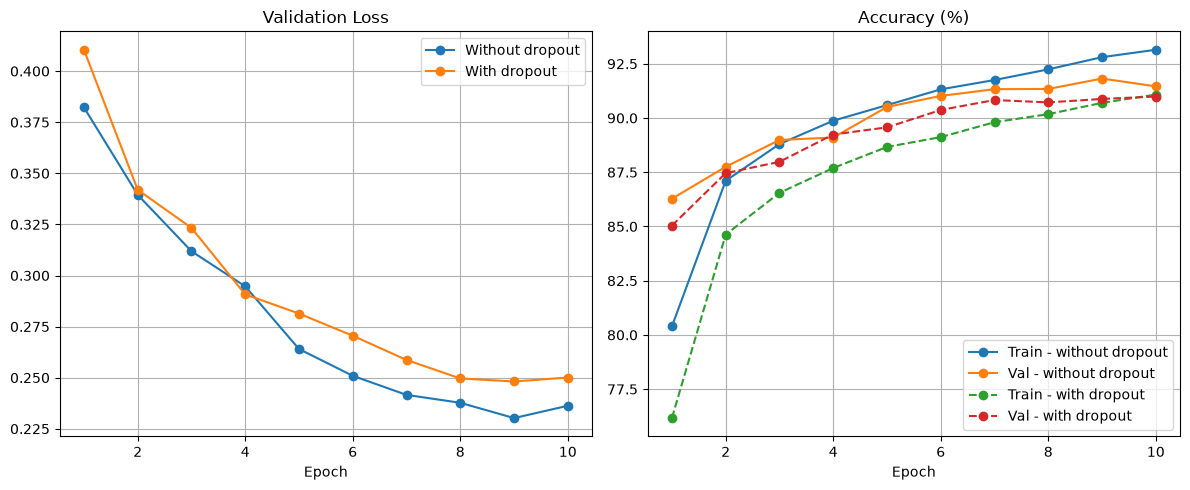

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(epochs_axis, history["val_loss"], marker="o", label="Without dropout")
axes[0].plot(epochs_axis, history_dropout["val_loss"], marker="o", label="With dropout")
axes[0].set_title("Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_axis, history["train_acc"], marker="o", label="Train - without dropout")
axes[1].plot(epochs_axis, history["val_acc"], marker="o", label="Val - without dropout")
axes[1].plot(epochs_axis, history_dropout["train_acc"], marker="o", linestyle="--", label="Train - with dropout")
axes[1].plot(epochs_axis, history_dropout["val_acc"], marker="o", linestyle="--", label="Val - with dropout")
axes[1].set_title("Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Comparison: with and without dropout

With dropout, the training accuracy is lower (about 91% vs 93% at epoch 10), because half of the hidden neurons are turned off during training. The gap between training and validation accuracy almost disappears (about 0% vs 1.5%), so dropout reduces overfitting. However, the validation accuracy is not better (about 91% vs 91.5%) and the validation loss is slightly higher (0.250 vs 0.236). The model with dropout also learns more slowly.

Dropout dosen't always improve performance. It is useful when the model overfits a lot. Our baseline model only had a small overfitting, so dropout mostly slowed down learning instead of improving the validation results.

# Part VII — Saving and loading the network

## 27. Save the learned weights

The learned parameters can be stored using:

```python
torch.save(model.state_dict(), filename)
```
Save the model as:

```text
fashion_cnn.pth
```

In [43]:
# TODO: Save model weights.

torch.save(model.state_dict(), "fashion_cnn.pth")

print("Model weights saved.")

Model weights saved.


## 28. Reload the model

To reload the model:

1. create a new instance of the same architecture;
2. load the saved `state_dict`;
3. move the model to the required device;
4. switch to evaluation mode.
Reload the saved model and verify its test accuracy.

In [44]:
loaded_model = FashionCNN().to(device)

loaded_model.load_state_dict(
    torch.load(
        "fashion_cnn.pth",
        map_location=device,
    )
)

loaded_model.eval()

loaded_test_loss, loaded_test_accuracy = evaluate(
    loaded_model,
    test_loader,
    criterion,
    device,
)

print(f"Reloaded model test accuracy: {loaded_test_accuracy:.2f}%")

Reloaded model test accuracy: 90.78%


# Part VIII — CNN design challenge

## 29. Architecture experiment

Modify **one factor at a time**.

Possible experiments:

- increase the first convolution layer from 16 to 32 filters;
- increase the second convolution layer from 32 to 64 filters;
- add a third convolutional layer;
- remove one pooling layer;
- change kernel size from 3 × 3 to 5 × 5;
- replace ReLU with GELU;
- add dropout;
- change the learning rate;
- change the batch size;
- increase the number of epochs.

For every experiment, record:

| Experiment | Parameters changed | Train Acc. | Val. Acc. | Test Acc. |
|---|---|---:|---:|---:|
| Baseline | — | | | |
| Experiment 1 | | | | |
| Experiment 2 | | | | |
| Experiment 3 | | | | |

### Important

Change **one main factor at a time**. Otherwise, you will not know which modification caused the performance difference.

In [45]:
class ExperimentCNN(nn.Module):
    def __init__(self, c1=16, c2=32, third_conv=False, activation=nn.ReLU):
        super().__init__()

        layers = [
            nn.Conv2d(1, c1, kernel_size=3, padding=1), activation(), nn.MaxPool2d(2),   # -> c1 x 14 x 14
            nn.Conv2d(c1, c2, kernel_size=3, padding=1), activation(), nn.MaxPool2d(2),  # -> c2 x 7 x 7
        ]
        out_channels = c2

        if third_conv:
            # third conv without pooling, to keep a 7 x 7 size
            layers += [nn.Conv2d(c2, 64, kernel_size=3, padding=1), activation()]        # -> 64 x 7 x 7
            out_channels = 64

        self.features = nn.Sequential(*layers)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(out_channels * 7 * 7, 128),
            activation(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [46]:
def run_experiment(name, change, model, epochs=10, lr=0.001):
    torch.manual_seed(SEED)   # same starting conditions for every experiment
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
        print(f"{name} | Epoch {epoch + 1:2d}/{epochs} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

    test_loss, test_acc = evaluate(model, test_loader, criterion, device)
    return {"Experiment": name, "Parameters changed": change,
            "Train Acc": round(train_acc, 2), "Val Acc": round(val_acc, 2), "Test Acc": round(test_acc, 2)}

In [47]:
results = []

# Baseline and dropout: already trained, we reuse their results
_, test_acc_dropout = evaluate(model_dropout, test_loader, criterion, device)
results.append({"Experiment": "Baseline", "Parameters changed": "—",
                "Train Acc": round(history["train_acc"][-1], 2), "Val Acc": round(history["val_acc"][-1], 2),
                "Test Acc": round(test_accuracy, 2)})
results.append({"Experiment": "Experiment 1", "Parameters changed": "Dropout p=0.5",
                "Train Acc": round(history_dropout["train_acc"][-1], 2), "Val Acc": round(history_dropout["val_acc"][-1], 2),
                "Test Acc": round(test_acc_dropout, 2)})

# New experiments (one change at a time)
results.append(run_experiment("Experiment 2", "Conv2: 32 -> 64 filters", ExperimentCNN(c2=64)))
results.append(run_experiment("Experiment 3", "Third conv layer (64 filters)", ExperimentCNN(third_conv=True)))
results.append(run_experiment("Experiment 4", "ReLU -> GELU", ExperimentCNN(activation=nn.GELU)))

Experiment 2 | Epoch  1/10 | Train Acc: 81.67% | Val Acc: 87.18%
Experiment 2 | Epoch  2/10 | Train Acc: 88.21% | Val Acc: 88.38%
Experiment 2 | Epoch  3/10 | Train Acc: 90.06% | Val Acc: 89.56%
Experiment 2 | Epoch  4/10 | Train Acc: 91.11% | Val Acc: 90.86%
Experiment 2 | Epoch  5/10 | Train Acc: 91.91% | Val Acc: 91.31%
Experiment 2 | Epoch  6/10 | Train Acc: 92.66% | Val Acc: 90.83%
Experiment 2 | Epoch  7/10 | Train Acc: 93.22% | Val Acc: 91.23%
Experiment 2 | Epoch  8/10 | Train Acc: 93.94% | Val Acc: 92.25%
Experiment 2 | Epoch  9/10 | Train Acc: 94.42% | Val Acc: 91.68%
Experiment 2 | Epoch 10/10 | Train Acc: 95.16% | Val Acc: 91.89%
Experiment 3 | Epoch  1/10 | Train Acc: 80.19% | Val Acc: 86.81%
Experiment 3 | Epoch  2/10 | Train Acc: 87.88% | Val Acc: 88.25%
Experiment 3 | Epoch  3/10 | Train Acc: 89.70% | Val Acc: 89.52%
Experiment 3 | Epoch  4/10 | Train Acc: 90.80% | Val Acc: 90.98%
Experiment 3 | Epoch  5/10 | Train Acc: 91.63% | Val Acc: 91.26%
Experiment 3 | Epoch  6/1

In [48]:
import pandas as pd
pd.DataFrame(results)

,Experiment,Parameters changed,Train Acc,Val Acc,Test Acc
0,Baseline,—,93.15,91.46,90.78
1,Experiment 1,Dropout p=0.5,91.08,90.99,90.42
2,Experiment 2,Conv2: 32 -> 64 filters,95.16,91.89,91.56
3,Experiment 3,Third conv layer (64 filters),94.89,91.86,91.01
4,Experiment 4,ReLU -> GELU,95.11,91.89,91.31


## 30. Final questions

Answer the following in your own words.

1. Why are convolutional layers particularly suitable for images?
2. What is weight sharing in a CNN?
3. What is a receptive field?
4. What is the role of pooling?
5. What is the purpose of flattening?
6. What does the final linear layer represent?
7. What are logits?
8. Why is Softmax not required before `CrossEntropyLoss` in PyTorch?
9. What does `loss.backward()` calculate?
10. What does `optimizer.step()` do?
11. Why do we call `optimizer.zero_grad()`?
12. What is the difference between `model.train()` and `model.eval()`?
13. Why do we use `torch.no_grad()` during evaluation?
14. Why is validation loss important even when training loss is decreasing?
15. Why should the test set be used only at the end?
16. How would you recognize overfitting from the training curves?
17. How would you recognize underfitting?
18. Which Fashion-MNIST classes were the most difficult for your model?
19. What architectural change gave your best validation accuracy?

### Answers

1. They examine small groups of neighboring pixels so they preserve the image structure and find patterns like edges anywhere in the image.

2. The same kernel is applied to the entire image, so the network requires fewer parameters.

3. The part of the image a neuron can “see”. It increases in size in deeper layers.

4. It reduces the dimensionality of the feature maps and retains the most important values.

5. It converts the feature maps into a vector for the linear layers to use.

6. It gives a score for each of the 10 classes.

7. Logits are the raw class scores, before Softmax.

8. Softmax is already done in CrossEntropyLoss.

9. It computes the gradient of the loss relative to each weight.

10. It updates the weights with the gradients.

11. To reset the gradients as PyTorch adds them up by default.

12. model.train() is for training (dropout on), model.eval() is for testing (dropout off).

13. During evaluation we do not need gradients, so it is faster and uses less memory.

14. Because it tells if the model works on new images. If it gets worse, the model is overfitting.

15. This keeps the test score fair and doesn't go into model selection.

16. The training loss keeps going down and the validation loss keeps going up.

17. Loss on training and validation are high.

18. Shirt (76.20%), then T-shirt/top, Coat and Pullover since they look very similar.

19. Increasing the second convolution layer from 32 to 64 filters and replacing ReLU with GELU gave the best validation accuracy (91.89%), but the improvement over the baseline is small (+0.4%).

# Optional advanced challenge

If you finish early, try one or more of the following.

### Challenge A — Normalization

Add image normalization using:

```python
transforms.Normalize((0.5,), (0.5,))
```

Retrain the model and compare the results.

### Challenge B — Batch normalization

Add:

```python
nn.BatchNorm2d(...)
```
after convolutional layers.

### Challenge E — Your own CNN

Design a completely new CNN subject to the following rule:

> The test set must not be used to choose your architecture.

Choose your architecture using the **validation set**, then report the test accuracy only once your design is finalized.

---

# Submission - import the CIFAR 10 data set and answer all the questions from this script

Submit:

1. your completed `.ipynb` notebook;
2. all requested plots;
3. answers to the written questions;
4. the final test accuracy;
5. a short comparison of at least two CNN architectures.

Your notebook should run sequentially from the first cell to the last cell without errors.

Note:Downloding the data set can take some time.

In [49]:
#TO import the CIFAR - 10 data set, use the following code: 
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Convert images to PyTorch tensors
transform = transforms.ToTensor()

# Download CIFAR-10 training dataset
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download CIFAR-10 test dataset
test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

# Inspect one sample
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

100%|██████████| 170M/170M [37:49<00:00, 75.1kB/s]   


Training samples: 50000
Test samples: 10000
Image shape: torch.Size([3, 32, 32])
Label: 6
